# Red Cedar — Quick Start

This notebook is a quick way to get started with Red Cedar. It shows how to train a quantum machine learning model on classified samples (samples whose class is known), and then use that model to classify samples whose class is not yet known.

The steps:
1. Train a quantum model on a CSV file
2. Classify samples using the trained model
3. Check the predicted classes
4. See which input features the model relies on

The data is the Wisconsin breast cancer dataset (WDBC). Each row is a tumor sample: 30 measurements (the *features*) and a diagnosis (the *class*), `M` for malignant or `B` for benign. The notebook uses two files in the `data/` folder:
- `wdbc_train.csv`: 455 classified samples, with their diagnosis, to train the model.
- `wdbc_unclassified.csv`: 114 other samples, with the measurements only, for the trained model to classify.

The same steps work for any table of samples with a class, such as equipment readings classified as *normal* or *faulty*, or transactions as *legitimate* or *fraudulent*. This is a demonstration on a public dataset, not a medical tool.

All computation happens on the Red Cedar server; this notebook sends requests and shows the results. The Quick Start page of the documentation shows the same steps for your own data, and the [User Guide](https://coherent-computing.github.io/redcedar/user_guide/) describes every SDK function.

In [1]:
# The two data files described above
train_file = "data/wdbc_train.csv"                 # 455 classified samples (diagnosis known), to train on
unclassified_file = "data/wdbc_unclassified.csv"   # 114 samples, measurements only: diagnosis not yet known

In [2]:
import redcedar

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

# Developers with the Red Cedar source installed (pip install -e) can use local mode,
# which runs Red Cedar in this process, with no server:
# client = redcedar.connect(local=True)

{'ok': True, 'server_version': 'unknown (not a git checkout, no VERSION file)', 'sdk_version': '0.94.0'}


## 1. Train a model

Training imprints the patterns in your data onto a quantum circuit, optimizing its parameters so that the quantum state it produces best links each sample's features to its class. `training.run()` takes the path of a CSV file with the class in the last column; the SDK uploads it and the server trains the model.

**How the model works.** A Red Cedar model is a quantum circuit. A row's features are encoded on its qubits, the circuit applies quantum operations whose adjustable settings are the *parameters*, and measuring the circuit gives the class. Training adjusts the parameters step by step; each *parameter update* makes the correct class more likely for the training rows.

**Layers.** The circuit is built in layers, each adding operations and parameters so the model can capture more complex patterns. Layers are trained one at a time, each starting from the parameters the one before found, and each finished layer is saved as a model of its own. More layers often, but not always, improve the accuracy.

**Settings.** Here 6 qubits and 2 layers, which trains in about a minute; `seed` makes the run repeatable. `dimension_reduction: "none"` keeps each original measurement as it is (by default, Red Cedar first combines the measurements into new features), so that explainable AI in section 4 can name the measurements the model relies on.

After each layer the server reports the **test accuracy**: the share of the rows it set aside from the file (20%), which the model does not train on, that the model classifies correctly.

More in the User Guide: [Training](https://coherent-computing.github.io/redcedar/user_guide/#training), [Settings](https://coherent-computing.github.io/redcedar/user_guide/#settings). `04_training_in_depth.ipynb` shows how the loss and accuracy change during training.

In [3]:
result = client.training.run(train_file, verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
    "dimension_reduction": "none",   # keep the original measurements (see Settings above)
})

train_id = result["train_id"]
print(f"\nModel ID: {train_id}")
print(f"Training time: {result['elapsed_seconds']}s")
for layer, v in result["validation"].items():
    print(f"Layer {layer}: test accuracy {v['test_accuracy']:.1%}")

  [  5%] Starting: layers 1-2

  [  5%] Layer 1/2           

  [  5%] Layer 1/2 .


  Layer 1: test accuracy 85.7%


  [ 50%] Layer 2/2

  [ 50%] Layer 2/2 .

... (2 outputs left out)

  [ 50%] Layer 2/2 ....


  Layer 2: test accuracy 85.7%


  [100%] Done.



Model ID: b59c4323-9feb-44ac-8a2a-4615cd52f81f
Training time: 12.0s
Layer 1: test accuracy 85.7%
Layer 2: test accuracy 85.7%


## 2. Classify samples using the trained model

Now we apply the trained model to the 114 samples in `wdbc_unclassified.csv`, whose diagnosis is not yet known. For each one it predicts the class, `M` or `B`, with a confidence: the probability the model gives that class.

`inference.run()` matches the file's columns to the training file's by name (using a trained model on samples it hasn't seen is called *inference*), and `output=` writes the predictions to `wdbc_unclassified_predicted.csv`. More in the User Guide: [Predictions](https://coherent-computing.github.io/redcedar/user_guide/#predictions).

  [  5%] Loading model...

  [ 10%] Loading test data...

  [ 30%] Loading trained model...

  [ 40%] Reading new rows...     

  [ 50%] Running the model on 114 rows...

  [100%] Done.                           



Of the 114 unclassified samples, the model classifies 52 as malignant (M) and 62 as benign (B).

The first 10:
  Sample  Predicted       Confidence
       1  Malignant (M)   72%
       2  Malignant (M)   72%
       3  Malignant (M)   72%
       4  Malignant (M)   72%
       5  Benign (B)      74%
       6  Malignant (M)   72%
       7  Malignant (M)   72%
       8  Malignant (M)   72%
       9  Benign (B)      74%
      10  Malignant (M)   72%


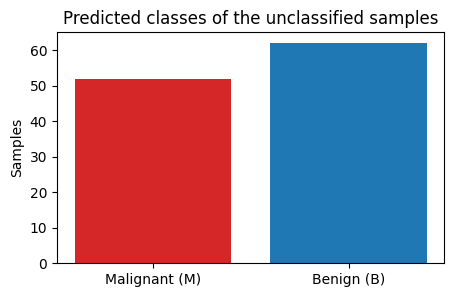

In [4]:
import matplotlib.pyplot as plt

CLASS_NAMES = {"M": "Malignant (M)", "B": "Benign (B)"}

def plot_predicted_classes(predicted):
    """Print how many samples got each class and the first 10 with their confidence; plot the counts."""
    counts = {c: sum(str(r["prediction"]) == c for r in predicted) for c in CLASS_NAMES}
    print(f"\nOf the {len(predicted)} unclassified samples, the model classifies "
          f"{counts['M']} as malignant (M) and {counts['B']} as benign (B).")
    print("\nThe first 10:")
    print(f"  {'Sample':>6}  {'Predicted':<14}  Confidence")
    for i, r in enumerate(predicted[:10], start=1):
        c = str(r["prediction"])
        print(f"  {i:>6}  {CLASS_NAMES[c]:<14}  {r['probabilities'][c]:.0%}")
    plt.figure(figsize=(5, 3))
    plt.bar([CLASS_NAMES[c] for c in counts], list(counts.values()), color=["tab:red", "tab:blue"])
    plt.ylabel("Samples")
    plt.title("Predicted classes of the unclassified samples")
    plt.show()

# Classify the samples and show the results
results = client.inference.run(train_id, unclassified_file, output="wdbc_unclassified_predicted.csv", verbose=True)
predicted = results["predictions"]
plot_predicted_classes(predicted)

## 3. Check the predicted classes

To see how well the model does, we compare its predicted classes with the actual ones. These samples come from a public dataset, so their actual diagnoses are known: they are in `data/wdbc_unclassified_actual.csv`, which the model never sees. With your own data there would be no such file.

Unlike the test accuracy in section 1, which uses rows set aside from the training file, this check uses a separate file, as a trained model is used in practice.

In [5]:
import csv
with open("data/wdbc_unclassified_actual.csv", newline="") as f:
    actual = [row["diagnosis"] for row in csv.DictReader(f)]

correct = sum(str(r["prediction"]) == a for r, a in zip(predicted, actual))
print(f"{correct} of {len(actual)} classified correctly ({correct / len(actual):.1%})")
for c in CLASS_NAMES:
    right = sum(str(r["prediction"]) == a == c for r, a in zip(predicted, actual))
    print(f"  {CLASS_NAMES[c]}: {right} of {actual.count(c)} classified correctly")

104 of 114 classified correctly (91.2%)
  Malignant (M): 42 of 42 classified correctly
  Benign (B): 62 of 72 classified correctly


## 4. Which features the model relies on

Explainable AI maps each data qubit back to the input feature it encodes and measures how much that qubit influences the prediction. A feature encoded on more than one qubit gets one importance: the probability that any of its qubits reads 1. More in the User Guide: [Explainable AI](https://coherent-computing.github.io/redcedar/user_guide/#explainable-ai).

  [  5%] Loading model...

  [ 10%] Loading data... 

  [ 20%] Loading trained model...

  [ 30%] Analyzing 1 class qubit(s)...

  [ 30%] Class qubit 1/1...           

  [100%] Done.             


  Qubit 0: worst_perimeter (importance 57.5%)
  Qubit 2: worst_radius (importance 23.4%)
  Qubit 1: worst_area (importance 14.7%)
  Qubit 3: mean_concave_points (importance 12.2%)
  Qubit 4: worst_concave_points (importance 8.8%)


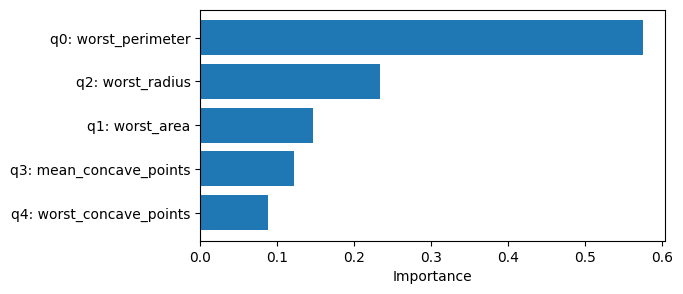

In [6]:
def qubits_label(feature, prefix="Qubit"):
    """The data qubits holding a feature: "Qubit 0", or "Qubits 0–2" for a feature on several."""
    ids = [q["qubit"] for q in feature["qubits"]]
    return f"{prefix} {ids[0]}" if len(ids) == 1 else f"{prefix}s {ids[0]}–{ids[-1]}"

def plot_feature_importance(features):
    """Print each feature's data qubits and importance, most important first; plot them."""
    for f in features:
        print(f"  {qubits_label(f)}: {f['feature_name']} (importance {f['importance']:.1%})")
    plt.figure(figsize=(6, 3))
    plt.barh([f"{qubits_label(f, 'q').replace('q ', 'q').replace('qs ', 'q')}: {f['feature_name']}" for f in features],
             [f["importance"] for f in features])
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.show()

# Explain the model and show the results (one entry per feature, most important first)
explanation = client.explainable.run(train_id, verbose=True)
plot_feature_importance(explanation["feature_importances"])

## Next steps

- `02_dataset_analysis.ipynb`: explore a dataset before training, or analyze your own CSV file
- `03_training_settings.ipynb`: settings you can change, one section per setting
- `04_training_in_depth.ipynb`: training loss and accuracy during training, layers, testing on the rows the server set aside (`training.evaluate()`), test accuracy over the course of training, choosing the data, reusing models, stopping a job